In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
%matplotlib inline

In [5]:
def dft_matrix(N):
    n = np.arange(N)
    return np.exp(-2j*np.pi*np.outer(n, n)/N)

x = np.array([0, 1, 2, 3])
X = dft_matrix(4) @ x
print(np.round(X, 4))                          # expect [6, -2+2j, -2, -2-2j]
print(np.allclose(X, np.fft.fft(x)))           # True
x_back = (dft_matrix(4).conj() @ X) / 4        # IDFT
print(np.round(x_back.real, 6))                # [0. 1. 2. 3.]

[ 6.+0.j -2.+2.j -2.-0.j -2.-2.j]
True
[0. 1. 2. 3.]


In [6]:
xa = np.array([1, 0, -1, 0])
print(np.round(dft_matrix(4) @ xa, 4))         # [0, 2, 0, 2]

[0.+0.j 2.+0.j 0.-0.j 2.+0.j]


In [7]:
def bit_reverse_indices(N):
    bits = int(np.log2(N))
    return np.array([int(format(i, f"0{bits}b")[::-1], 2) for i in range(N)])

print(bit_reverse_indices(8))                  # expect [0 4 2 6 1 5 3 7]

[0 4 2 6 1 5 3 7]


In [8]:
def fft_iterative(x):
    x = np.asarray(x, dtype=complex)
    N = len(x)
    x = x[bit_reverse_indices(N)].copy()            # stage 0: reorder
    size = 2
    while size <= N:                                # stages: 2-, 4-, 8-point ...
        half = size // 2
        W = np.exp(-2j*np.pi*np.arange(half)/size)  # twiddle factors
        for start in range(0, N, size):
            top = x[start:start+half].copy()
            bot = x[start+half:start+size] * W
            x[start:start+half] = top + bot         # butterfly upper output
            x[start+half:start+size] = top - bot    # butterfly lower output
        size *= 2
    return x

In [9]:
x = np.random.randn(1024)
print(np.allclose(fft_iterative(x), np.fft.fft(x)))

True


In [10]:
def fft_iterative_verbose(x):
    x = np.asarray(x, dtype=complex)
    N = len(x)
    x = x[bit_reverse_indices(N)].copy()
    print("after bit-reversal:", np.round(x, 4))
    size = 2
    while size <= N:
        half = size // 2
        W = np.exp(-2j*np.pi*np.arange(half)/size)
        print(f"\n{size}-point stage, twiddles W =", np.round(W, 4))
        for start in range(0, N, size):
            top = x[start:start+half].copy()
            bot = x[start+half:start+size] * W
            x[start:start+half] = top + bot
            x[start+half:start+size] = top - bot
            print(f"  block [{start}:{start+size}]: top={np.round(top,4)}, bot*W={np.round(bot,4)}")
        print("  after stage:", np.round(x, 4))
        size *= 2
    return x

fft_iterative_verbose([0, 1, 2, 3])

after bit-reversal: [0.+0.j 2.+0.j 1.+0.j 3.+0.j]

2-point stage, twiddles W = [1.-0.j]
  block [0:2]: top=[0.+0.j], bot*W=[2.+0.j]
  block [2:4]: top=[1.+0.j], bot*W=[3.+0.j]
  after stage: [ 2.+0.j -2.+0.j  4.+0.j -2.+0.j]

4-point stage, twiddles W = [1.-0.j 0.-1.j]
  block [0:4]: top=[ 2.+0.j -2.+0.j], bot*W=[ 4.+0.j -0.+2.j]
  after stage: [ 6.+0.j -2.+2.j -2.+0.j -2.-2.j]


array([ 6.+0.j, -2.+2.j, -2.+0.j, -2.-2.j])

In [11]:
import time

def timeit(f, reps):
    best = np.inf
    for _ in range(reps):
        t0 = time.perf_counter(); f(); best = min(best, time.perf_counter() - t0)
    return best

Ns = 2**np.arange(6, 13)                    # 64, 128, ..., 4096
t_dft, t_it, t_np = [], [], []
rng = np.random.default_rng(0)
for N in Ns:
    x = rng.standard_normal(N)
    t_dft.append(timeit(lambda: dft_matrix(N) @ x, 3))
    t_it.append(timeit(lambda: fft_iterative(x), 3))
    t_np.append(timeit(lambda: np.fft.fft(x), 20))
    print(f"N={N:5d}  dft_matrix@x = {t_dft[-1]*1e3:9.3f} ms | fft_iterative = {t_it[-1]*1e3:8.3f} ms | np.fft.fft = {t_np[-1]*1e3:8.4f} ms")
t_dft, t_it, t_np = map(np.array, (t_dft, t_it, t_np))

N=   64  dft_matrix@x =     0.300 ms | fft_iterative =    0.320 ms | np.fft.fft =   0.0061 ms
N=  128  dft_matrix@x =     0.646 ms | fft_iterative =    0.474 ms | np.fft.fft =   0.0070 ms
N=  256  dft_matrix@x =     2.847 ms | fft_iterative =    0.913 ms | np.fft.fft =   0.0082 ms
N=  512  dft_matrix@x =    12.132 ms | fft_iterative =    1.905 ms | np.fft.fft =   0.0103 ms
N= 1024  dft_matrix@x =    45.185 ms | fft_iterative =    3.522 ms | np.fft.fft =   0.0153 ms
N= 2048  dft_matrix@x =   182.979 ms | fft_iterative =    7.140 ms | np.fft.fft =   0.0252 ms
N= 4096  dft_matrix@x =   723.075 ms | fft_iterative =   13.871 ms | np.fft.fft =   0.0467 ms


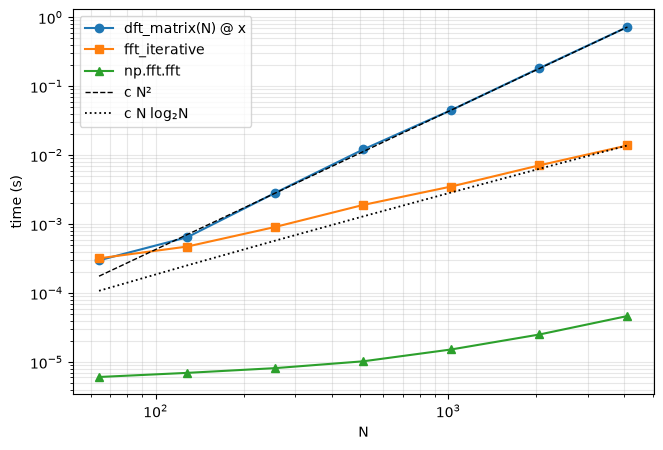

In [12]:
c2 = t_dft[-1] / Ns[-1]**2                          # c for c·N²
c1 = t_it[-1] / (Ns[-1]*np.log2(Ns[-1]))            # c for c·N·log2(N)

plt.figure(figsize=(7.5, 5))
plt.loglog(Ns, t_dft, "o-", label="dft_matrix(N) @ x")
plt.loglog(Ns, t_it, "s-", label="fft_iterative")
plt.loglog(Ns, t_np, "^-", label="np.fft.fft")
plt.loglog(Ns, c2*Ns**2, "k--", lw=1, label="c N²")
plt.loglog(Ns, c1*Ns*np.log2(Ns), "k:", lw=1.3, label="c N log₂N")
plt.xlabel("N"); plt.ylabel("time (s)"); plt.grid(True, which="both", alpha=0.3); plt.legend(); plt.show()

In [13]:
for name, t in [("dft_matrix", t_dft), ("fft_iterative", t_it), ("np.fft.fft", t_np)]:
    print(name, "slope =", round(np.polyfit(np.log(Ns), np.log(t), 1)[0], 2))

dft_matrix slope = 1.93
fft_iterative slope = 0.93
np.fft.fft slope = 0.48


C:\Users\AB GROUP\AppData\Local\Temp\ipykernel_21812\3097063319.py:4: RuntimeWarning: invalid value encountered in divide
  dtft = np.abs(np.sin(2*w)/np.sin(w/2))


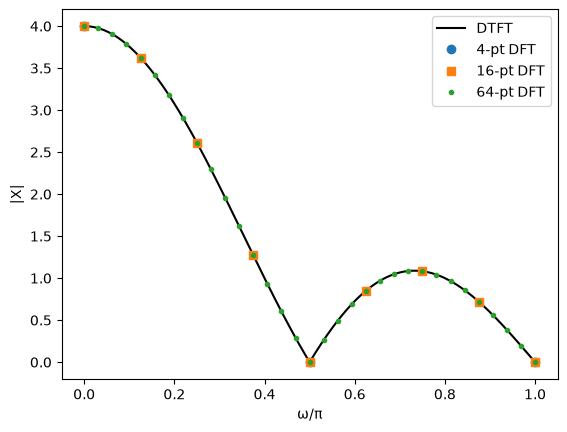

In [14]:
import numpy as np, matplotlib.pyplot as plt
x = np.array([1,1,1,1])
w = np.linspace(0, np.pi, 1000)
dtft = np.abs(np.sin(2*w)/np.sin(w/2))

plt.plot(w/np.pi, dtft, 'k', label='DTFT')
for N, m in [(4,'o'), (16,'s'), (64,'.')]:
    X = np.abs(np.fft.fft(x, N))[:N//2+1]
    plt.plot(np.arange(N//2+1)*2/N, X, m, label=f'{N}-pt DFT')
plt.xlabel('ω/π'); plt.ylabel('|X|'); plt.legend(); plt.show()

In [15]:
import time
x = np.random.randn(10_000); h = np.ones(501)/501
L, M = len(x), len(h)
N = 1 << int(np.ceil(np.log2(L+M-1)))      # 10500 -> 16384

t=time.perf_counter(); y1 = np.convolve(x, h); t1=time.perf_counter()-t
t=time.perf_counter()
y2 = np.fft.ifft(np.fft.fft(x,N)*np.fft.fft(h,N)).real[:L+M-1]
t2=time.perf_counter()-t
print(np.allclose(y1,y2), t1, t2, t1/t2)

# 4-point circular convolution
a = np.array([2,1.5,1,0.5]); b = np.array([1,0,1,0])
print(np.fft.ifft(np.fft.fft(a)*np.fft.fft(b)).real)   # [3. 2. 3. 2.]

True 0.0007429999968735501 0.0015969000014592893 0.4652764707837542
[3. 2. 3. 2.]


Analysis questions
1. Speed-up at N = 4096.
Direct DFT needs N² = 16.8 M multiplications. The FFT needs (N/2)·log₂N = 2048 × 12 = 24,576.
That is about 680× fewer operations. Read your actual measured ratio off your plot, since Python overhead will make it differ.
np.fft.fft is faster still because it runs compiled C (pocketfft) with no Python loop overhead. It is also vectorised and cache-optimised, and handles non-power-of-2 sizes with mixed radix.
2. Bit reversal in DIT. DIT repeatedly splits the input into even- and odd-indexed halves. Doing this fully makes the sequence end up in bit-reversed index order. Reordering the input first lets every butterfly stage work in place on adjacent pairs and produces the output in natural order.
3. Why pad to at least L+M−1. Linear convolution has length L+M−1. The DFT product gives circular convolution of length N. If N is smaller, the tail wraps around and overlaps the start (time-domain aliasing). Both sequences must also be length N so the DFTs can be multiplied point by point.
4. OFDM FFT rate.
FFTs per second = 1/66.7 µs = 15,000.
Multiplications per FFT = (2048/2) × 11 = 11,264.
Total ≈ 1.69 × 10⁸ complex multiplications per second (about 169 million).

I used Claude (Anthropic) as a study aid for Week 05. It helped me draft explanations for the zero-padding discussion in Task 5.5 and for the analysis questions, and it suggested code for the fast-convolution comparison in Task 5.6. I ran and checked all the code myself, confirmed that fft_iterative matches np.fft.fft, and produced the timing plot and speed-up figures from my own measurements. I compared the answers against the lecture notes and wrote the final explanations in my own words.